# Import Libraries

In [3]:
pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 10.0 MB 4.2 MB/s eta 0:00:01
     |████████████████████████████████| 233 kB 6.0 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import STL

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

# Load Dataset

In [5]:
import pandas as pd

url = "https://raw.githubusercontent.com/amandamich/Purchase_Patterns_Across_Data_Derived_Cafe_Demand_Regimes/main/Transaction%20Report%202025.csv"
df = pd.read_csv(url)

df.head()

,Outlet,Date,Time,Gross Sales,Discounts,Refunds,Net Sales,Gratuity,Tax,Total Collected,...,Other Note (Optional),Receipt Number,Collected By,Served By,Customer,Customer Phone,Items,Payment Method,Event Type,Reason of Refund
0,QUATRO,31-12-2025,21:54:10,80000.0,0.0,0.0,80000.0,0.0,0.0,80000.0,...,NaN,D8X0Y8,quatro,NaN,NaN,NaN,"SIGNATURE Coffee (Kopi Susu Lokal) x 2, BLENDS...",Cash,Payment,NaN
1,QUATRO,31-12-2025,21:52:43,73000.0,0.0,0.0,73000.0,0.0,0.0,73000.0,...,NaN,D8X0Y7,quatro,NaN,NaN,NaN,"SIGNATURE Coffee (Aren Latte), DESSERT (Poured...",Cash,Payment,NaN
2,QUATRO,31-12-2025,21:51:49,25000.0,0.0,0.0,25000.0,0.0,0.0,25000.0,...,NaN,D8X0Y6,quatro,NaN,NaN,NaN,SIGNATURE Coffee (Aren Latte),Other EDC,Payment,NaN
3,QUATRO,31-12-2025,21:38:35,40000.0,0.0,0.0,40000.0,0.0,0.0,40000.0,...,NaN,D8X0Y5,quatro,NaN,NaN,NaN,"BUNDLE (Berdua - KSL, AREN)",Cash,Payment,NaN
4,QUATRO,31-12-2025,21:37:18,146000.0,0.0,0.0,146000.0,0.0,0.0,146000.0,...,NaN,D8X0Y4,quatro,NaN,NaN,NaN,"DESSERT (Brownies cheesecake), Snack Suhu Ruan...",Cash,Payment,NaN


In [6]:
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Dataset shape: (39856, 21)

Columns:
['Outlet', 'Date', 'Time', 'Gross Sales', 'Discounts', 'Refunds', 'Net Sales', 'Gratuity', 'Tax', 'Total Collected', 'Total Amount', 'Other Note (Optional)', 'Receipt Number', 'Collected By', 'Served By', 'Customer', 'Customer Phone', 'Items', 'Payment Method', 'Event Type', 'Reason of Refund']

Data types:
Outlet                    object
Date                      object
Time                      object
Gross Sales              float64
Discounts                float64
Refunds                  float64
Net Sales                float64
Gratuity                 float64
Tax                      float64
Total Collected          float64
Total Amount             float64
Other Note (Optional)     object
Receipt Number            object
Collected By              object
Served By                float64
Customer                 float64
Customer Phone            object
Items                     object
Payment Method            object
Event Type                o

# Data Understanding

In [7]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Start date:", df["Date"].min())
print("End date:", df["Date"].max())

Start date: 2025-01-01 00:00:00
End date: 2025-12-31 00:00:00


In [8]:
print("Number of rows:", len(df))

print(
    "Number of transactions:",
    df["Receipt Number"].nunique()
)

print(
    "Number of products:",
    df["Items"].nunique()
)

Number of rows: 39856
Number of transactions: 39798
Number of products: 19745


Check missing values:

In [9]:
missing = df.isnull().sum()

missing[missing > 0]

Other Note (Optional)    39779
Served By                39856
Customer                 39856
Customer Phone           39855
Reason of Refund         39799
dtype: int64

Check Product:

In [10]:
df["Items"].value_counts().head(20)

Items
SIGNATURE Coffee (Aren Latte)               1814
CLASSIC COFFEE (Americano)                  1126
SIGNATURE Coffee (Kopi Susu Lokal)           921
MINI CHIFFON (MC1)                           754
AIR MINERAL                                  739
SIGNATURE Coffee (Butterscotch Machiato)     690
SIGNATURE Coffee (Caramel Machiato)          434
SIGNATURE Coffee (Pistachio Machiato)        376
MINI CHIFFON (MC2)                           355
BLENDS (Uji Matcha )                         334
CLASSIC COFFEE (Cappucino)                   317
SIGNATURE Coffee (Aren Latte) x 2            245
BLENDS (Dark Chocolate)                      241
SIGNATURE Coffee (Pandan Latte)              212
CLASSIC COFFEE (Cafe Latte)                  210
BLENDS (Strawberry Milk)                     200
Custom Amount                                186
CLASSIC COFFEE (Orange Americano )           177
TEA (Teh Tarik)                              158
BLENDS (Hazelnut Chocolate)                  138
Name: count, d

# Data Preparation

In [11]:
df = df.dropna(
    subset=[
        "Date",
        "Receipt Number",
        "Items"
    ]
).copy()

Making sure string is clean:

In [12]:
import re

df["Receipt Number"] = (
    df["Receipt Number"]
    .astype(str)
    .str.strip()
)

def clean_item_name(item_name):
    # Remove ' x N' pattern from item names (e.g., ' x 2', ' x 3')
    return re.sub(r' x \d+', '', item_name).strip()

df["Item Group"] = (
    df["Items"]
    .astype(str)
    .apply(clean_item_name)
    .str.strip()
)

Remove empty items:

In [13]:
df = df[
    (df["Receipt Number"] != "") &
    (df["Item Group"] != "")
].copy()

Remove 'Custom Amount' from Item Group, as it is not relevant:

In [14]:
df = df[df["Item Group"] != "Custom Amount"].copy()

# Build Daily Demand

Number of unique receipts per day = daily demand

In [15]:
daily_demand = (
    df.groupby("Date")["Receipt Number"]
      .nunique()
      .rename("demand")
      .to_frame()
)

In [16]:
full_date_range = pd.date_range(
    start=daily_demand.index.min(),
    end=daily_demand.index.max(),
    freq="D"
)

daily_demand = (
    daily_demand
    .reindex(full_date_range, fill_value=0)
)

daily_demand.index.name = "Date"

In [17]:
daily_demand.head()

,demand
Date,
2025-01-01,134
2025-01-02,136
2025-01-03,121
2025-01-04,122
2025-01-05,109


### Visualize Daily Demand

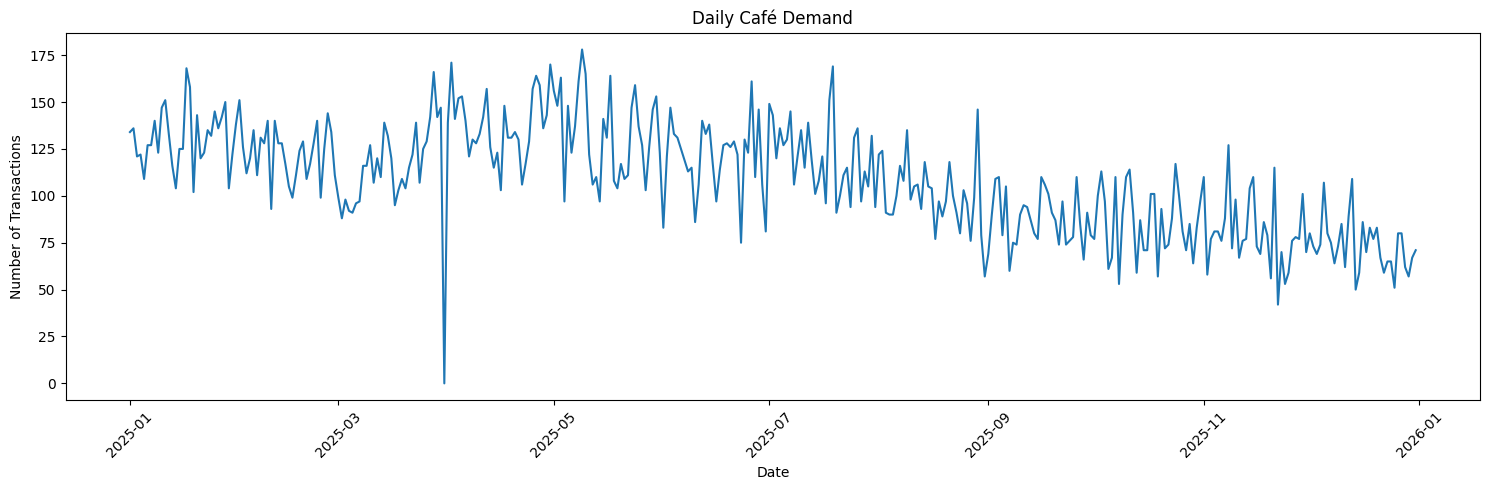

In [18]:
plt.figure(figsize=(15, 5))

plt.plot(
    daily_demand.index,
    daily_demand["demand"]
)

plt.title("Daily Café Demand")
plt.xlabel("Date")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# STL Decomposition

In [19]:
STL_PERIOD = 7

stl = STL(
    daily_demand["demand"],
    period=STL_PERIOD,
    robust=True
)

stl_result = stl.fit()

Saving components:

In [20]:
daily_demand["trend"] = stl_result.trend

daily_demand["seasonal"] = stl_result.seasonal

daily_demand["residual"] = stl_result.resid

daily_demand.head(10)

,demand,trend,seasonal,residual
Date,,,,
2025-01-01,134,118.620409,13.597481,1.782110
2025-01-02,136,120.340136,7.407644,8.252220
2025-01-03,121,122.088992,4.221970,-5.310962
2025-01-04,122,123.824987,8.351350,-10.176337
2025-01-05,109,125.509031,-13.498485,-3.010546
2025-01-06,127,127.133291,-1.474891,1.341600
2025-01-07,127,128.751923,-12.490573,10.738650
2025-01-08,140,130.648541,6.768045,2.583414
2025-01-09,123,131.436947,3.095853,-11.532800


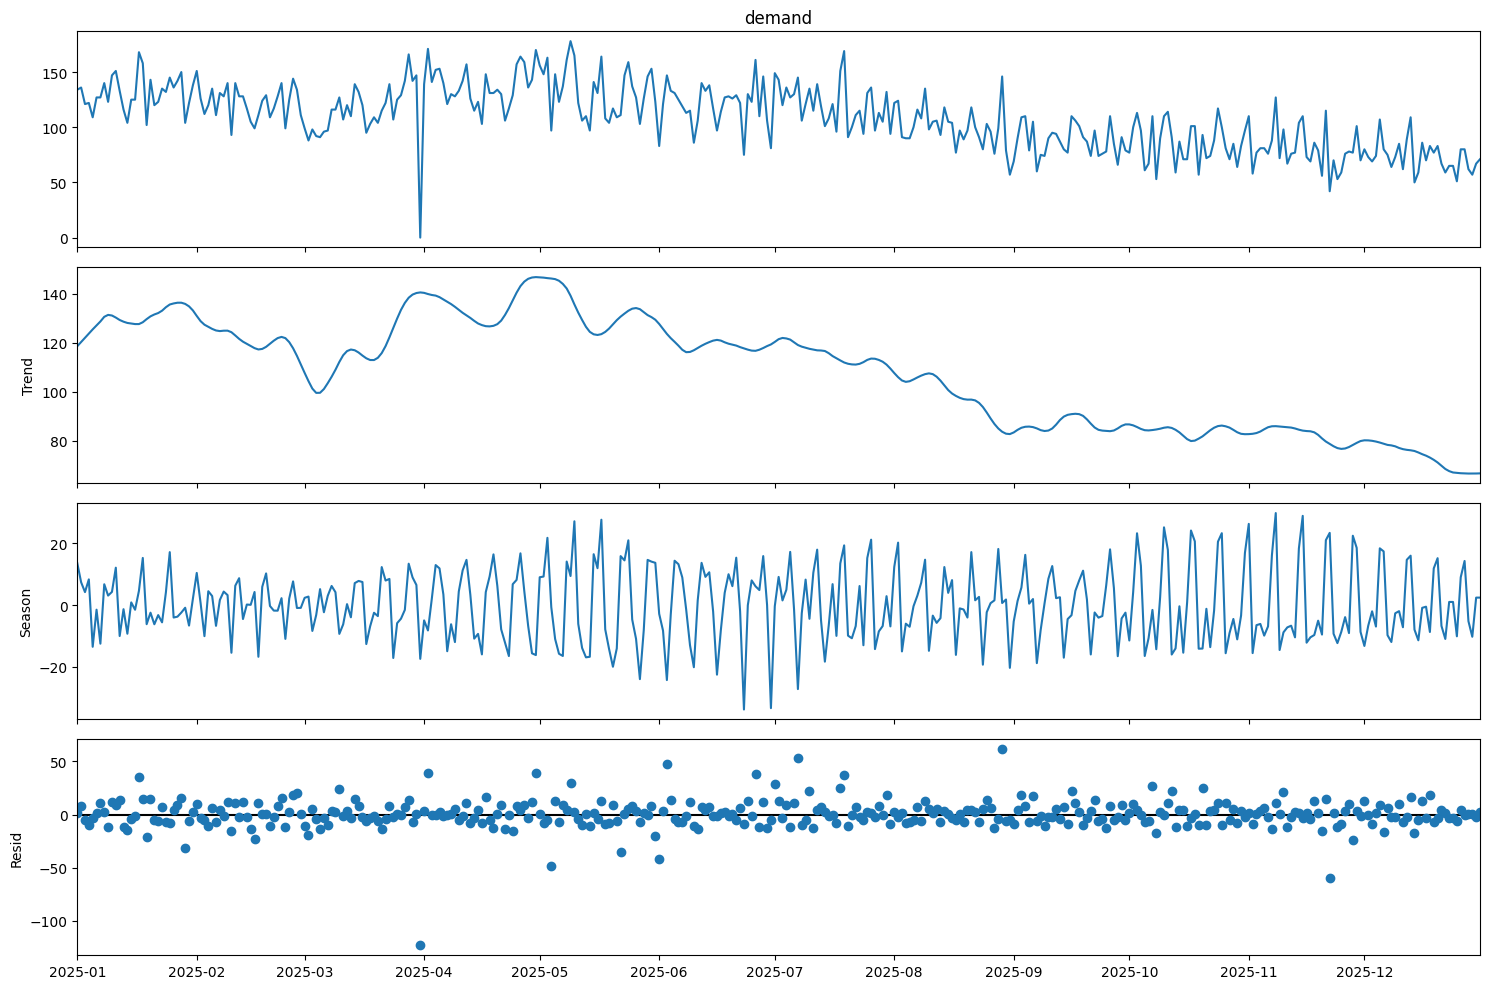

In [21]:
fig = stl_result.plot()

fig.set_size_inches(15, 10)

plt.tight_layout()
plt.show()

# Analyze Seasonal Component

In [22]:
daily_demand["seasonal"].describe()

count    365.000000
mean       0.054553
std       11.514273
min      -33.825208
25%       -8.275652
50%       -0.878303
75%        8.028974
max       29.838163
Name: seasonal, dtype: float64

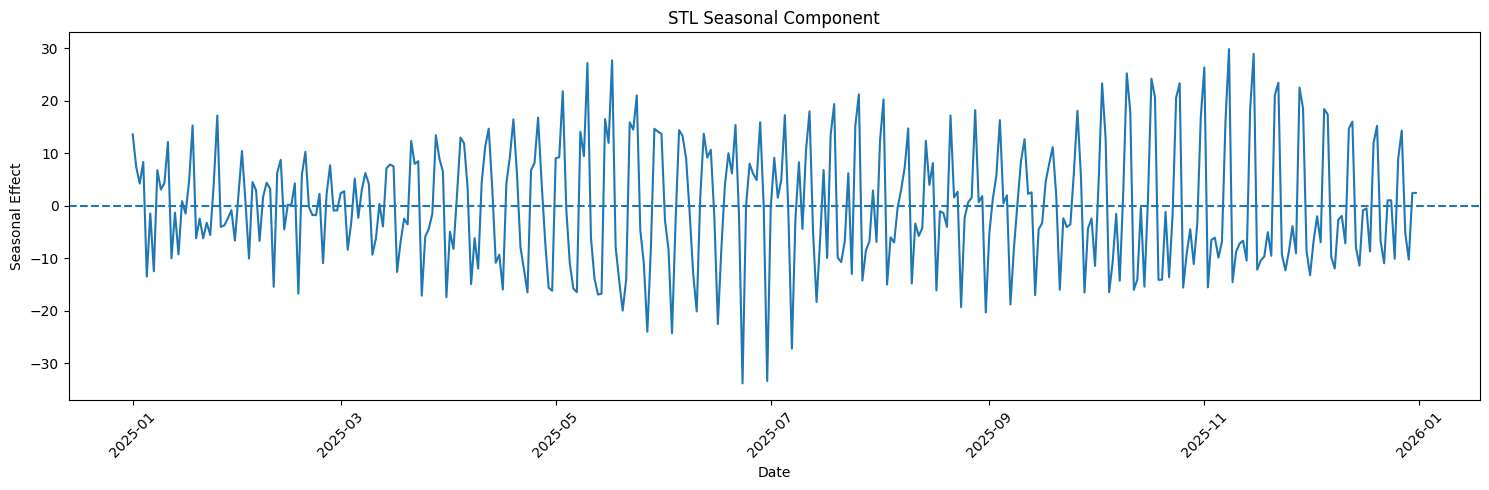

In [23]:
plt.figure(figsize=(15, 5))

plt.plot(
    daily_demand.index,
    daily_demand["seasonal"]
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("STL Seasonal Component")
plt.xlabel("Date")
plt.ylabel("Seasonal Effect")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Determining Number of Demand Regimes
using K-Means

In [24]:
X = daily_demand[
    ["seasonal"]
].values

In [25]:
silhouette_scores = {}

for k in range(2, 6):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X)

    score = silhouette_score(
        X,
        labels
    )

    silhouette_scores[k] = score

silhouette_scores

{2: np.float64(0.5687782686798811),
 3: np.float64(0.5491279166281894),
 4: np.float64(0.5380333338999533),
 5: np.float64(0.5279350934801235)}

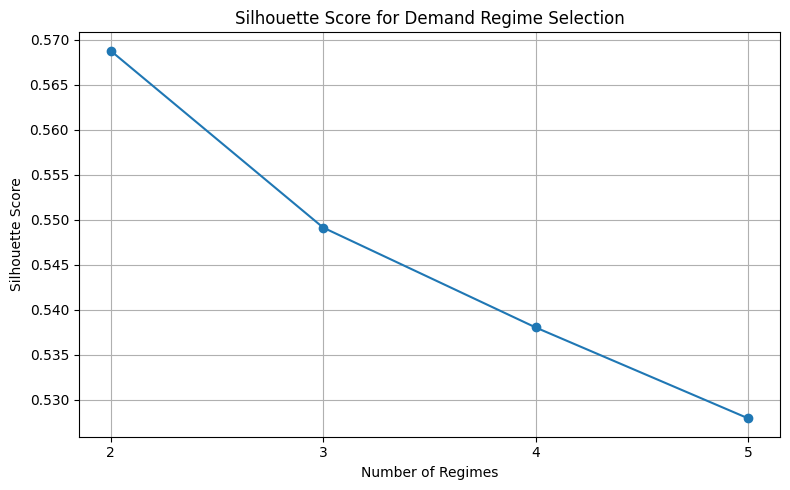

In [26]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(silhouette_scores.keys()),
    list(silhouette_scores.values()),
    marker="o"
)

plt.title(
    "Silhouette Score for Demand Regime Selection"
)

plt.xlabel("Number of Regimes")
plt.ylabel("Silhouette Score")

plt.xticks(range(2, 6))

plt.grid(True)

plt.tight_layout()
plt.show()

In [27]:
best_k = max(
    silhouette_scores,
    key=silhouette_scores.get
)

print("Optimal number of regimes:", best_k)

print(
    "Silhouette Score:",
    silhouette_scores[best_k]
)

Optimal number of regimes: 2
Silhouette Score: 0.5687782686798811


In [28]:
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)

daily_demand["cluster"] = (
    kmeans.fit_predict(X)
)

### Identify Regime Characteristics

In [29]:
cluster_summary = (
    daily_demand
    .groupby("cluster")["seasonal"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        min="min",
        max="max"
    )
    .sort_values("mean")
)

cluster_summary

,count,mean,median,min,max
cluster,,,,,
1,204,-8.269752,-6.975317,-33.825208,1.032186
0,161,10.602121,9.037832,1.335154,29.838163


Dari kedua batas cluster diatas, kita mendapatkan:
* **Cluster 1**

  Min = -34.28

  Max = +1.71
* **Cluster 0**

  Min = +1.80

  Max = +29.70

Ini menarik karena **tidak ada overlap** antara range kedua cluster:

Cluster 1: -34.28 ───────── +1.71

Cluster 0:                    +1.80 ─────── +29.70

                              ↑
                         gap ≈ 0.09

Artinya, berdasarkan seasonal component yang digunakan K-Means, kedua regime tersebut terpisah sangat jelas secara nilai seasonal component.

Ini bisa menjadi salah satu bukti pendukung bahwa pembagian dua regime memang masuk akal.

### Assign Demand Regime Names

In [30]:
sorted_clusters = (
    cluster_summary
    .sort_values("mean")
    .index
    .tolist()
)

regime_mapping = {
    sorted_clusters[0]: "Lower Seasonal Demand",
    sorted_clusters[1]: "Higher Seasonal Demand"
}

daily_demand["regime"] = (
    daily_demand["cluster"]
    .map(regime_mapping)
)

In [31]:
daily_demand["regime"].value_counts()

regime
Lower Seasonal Demand     204
Higher Seasonal Demand    161
Name: count, dtype: int64

### Regime Statistics

In [32]:
regime_order = [
    "Lower Seasonal Demand",
    "Higher Seasonal Demand"
]

regime_statistics = (
    daily_demand
    .groupby("regime")
    .agg(
        days=("demand", "count"),
        mean_demand=("demand", "mean"),
        median_demand=("demand", "median"),
        std_demand=("demand", "std"),
        mean_seasonal=("seasonal", "mean"),
        median_seasonal=("seasonal", "median"),
        min_demand=("demand", "min"),
        max_demand=("demand", "max")
    )
    .reindex(regime_order)
)

regime_statistics

,days,mean_demand,median_demand,std_demand,mean_seasonal,median_seasonal,min_demand,max_demand
regime,,,,,,,,
Lower Seasonal Demand,204,98.122549,97.5,26.804707,-8.269752,-6.975317,0,171
Higher Seasonal Demand,161,121.795031,123.0,24.994279,10.602121,9.037832,42,178


### Regimes Comparison

In [33]:
comparison = (
    daily_demand
    .groupby("regime")["demand"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .reindex(regime_order)
)

comparison

,count,mean,median,std,min,max
regime,,,,,,
Lower Seasonal Demand,204,98.122549,97.5,26.804707,0,171
Higher Seasonal Demand,161,121.795031,123.0,24.994279,42,178


In [34]:
lower_mean = comparison.loc[
    "Lower Seasonal Demand", "mean"
]

higher_mean = comparison.loc[
    "Higher Seasonal Demand", "mean"
]

difference = higher_mean - lower_mean

percentage_difference = (
    difference / lower_mean * 100
)

print("Mean demand difference:", difference)
print(
    "Percentage difference:",
    percentage_difference
)

Mean demand difference: 23.672482036292777
Percentage difference: 24.125425065712776


Artinya, secara rata-rata, demand pada Higher Seasonal Demand Regime sekitar 24,46 transaksi lebih banyak per hari dibandingkan Lower Seasonal Demand Regime.

Ini juga berarti mean demand Higher Seasonal Demand sekitar 24,72% lebih tinggi dibandingkan Lower Seasonal Demand.

Ini menunjukkan bahwa regime yang dibentuk berdasarkan seasonal component juga memiliki perbedaan pada observed daily demand.

**Days classified into the Higher Seasonal Demand Regime exhibited an average daily transaction volume approximately 24.72% higher than those classified into the Lower Seasonal Demand Regime.**

In [35]:
# Check maximum demand for each regime
daily_demand.groupby("regime")["demand"].max()

regime
Higher Seasonal Demand    178
Lower Seasonal Demand     171
Name: demand, dtype: int64

In [36]:
# Complete regime statistics
regime_statistics

,days,mean_demand,median_demand,std_demand,mean_seasonal,median_seasonal,min_demand,max_demand
regime,,,,,,,,
Lower Seasonal Demand,204,98.122549,97.5,26.804707,-8.269752,-6.975317,0,171
Higher Seasonal Demand,161,121.795031,123.0,24.994279,10.602121,9.037832,42,178


### Visualize Regime Distribution
A. Seasonal Component

<Figure size 1000x600 with 0 Axes>

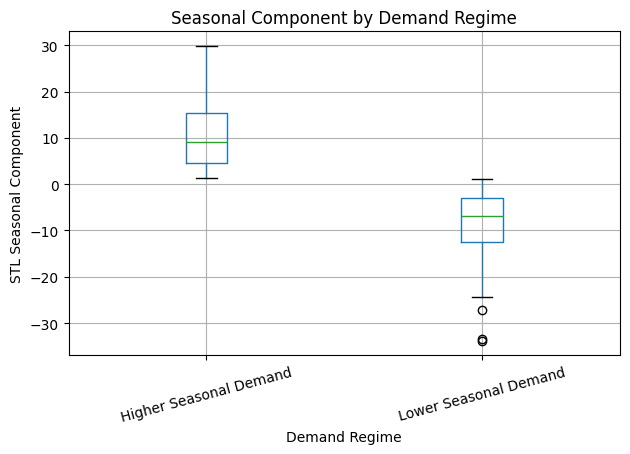

In [37]:
plt.figure(figsize=(10, 6))

daily_demand.boxplot(
    column="seasonal",
    by="regime"
)

plt.title(
    "Seasonal Component by Demand Regime"
)

plt.suptitle("")

plt.xlabel("Demand Regime")
plt.ylabel("STL Seasonal Component")

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

B. Daily Demand

<Figure size 1000x600 with 0 Axes>

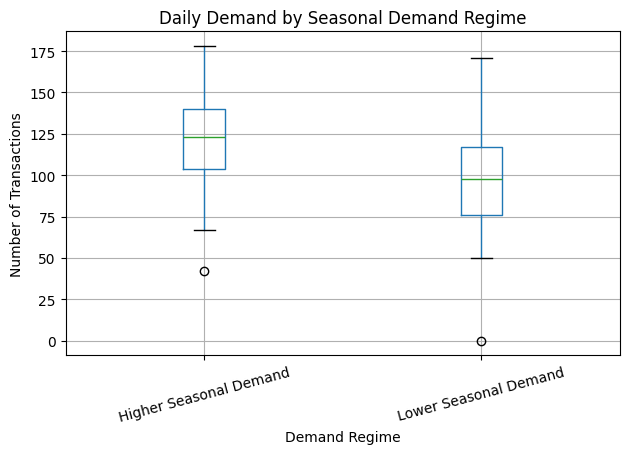

In [38]:
plt.figure(figsize=(10, 6))

daily_demand.boxplot(
    column="demand",
    by="regime"
)

plt.title(
    "Daily Demand by Seasonal Demand Regime"
)

plt.suptitle("")

plt.xlabel("Demand Regime")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

### Visualize Regime Over Time

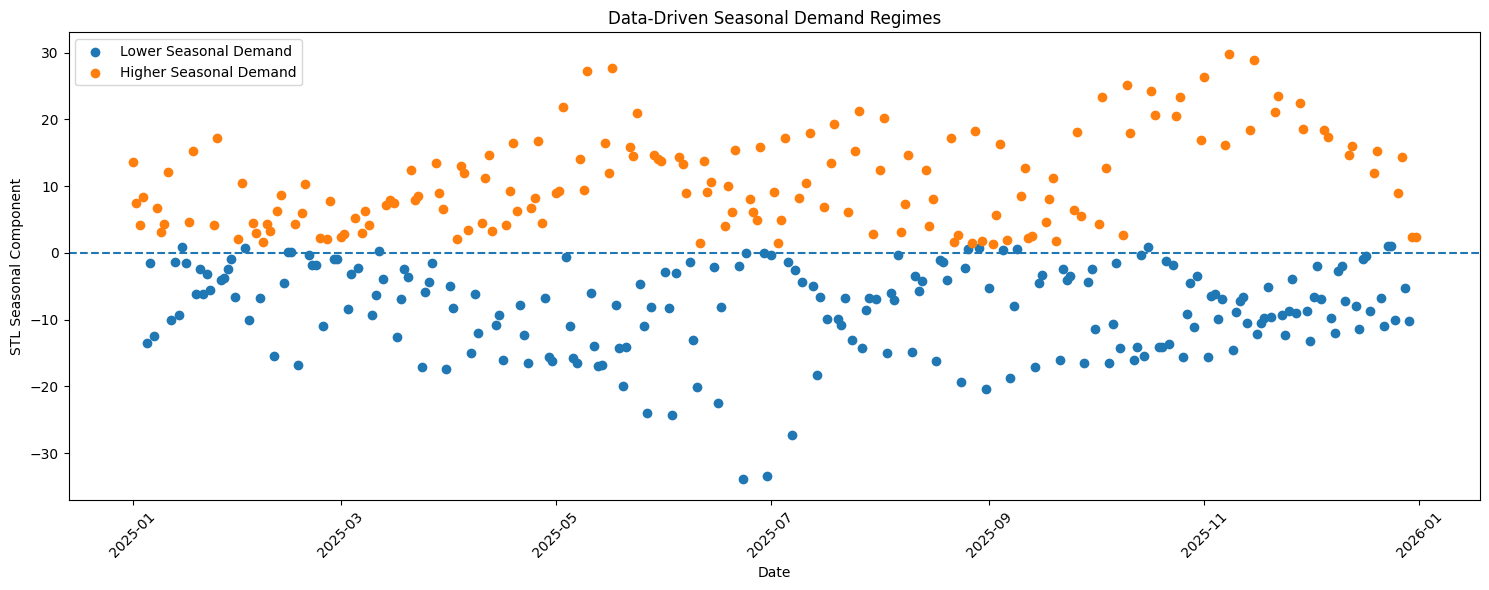

In [39]:
plt.figure(figsize=(15, 6))

for regime in regime_order:

    subset = daily_demand[
        daily_demand["regime"] == regime
    ]

    plt.scatter(
        subset.index,
        subset["seasonal"],
        label=regime
    )

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title(
    "Data-Driven Seasonal Demand Regimes"
)

plt.xlabel("Date")
plt.ylabel("STL Seasonal Component")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Assign Regime to Original Transactions

In [40]:
regime_lookup = (
    daily_demand["regime"]
    .rename("regime")
)

df["regime"] = df["Date"].map(regime_lookup)

In [41]:
df[
    [
        "Date",
        "Receipt Number",
        "Item Group",
        "regime"
    ]
].head(100)

,Date,Receipt Number,Item Group,regime
0,2025-12-31,D8X0Y8,"SIGNATURE Coffee (Kopi Susu Lokal), BLENDS (Da...",Higher Seasonal Demand
1,2025-12-31,D8X0Y7,"SIGNATURE Coffee (Aren Latte), DESSERT (Poured...",Higher Seasonal Demand
2,2025-12-31,D8X0Y6,SIGNATURE Coffee (Aren Latte),Higher Seasonal Demand
3,2025-12-31,D8X0Y5,"BUNDLE (Berdua - KSL, AREN)",Higher Seasonal Demand
4,2025-12-31,D8X0Y4,"DESSERT (Brownies cheesecake), Snack Suhu Ruan...",Higher Seasonal Demand
...,...,...,...,...
96,2025-12-30,D8X0VL,"BLENDS (Strawberry Matcha ), NASI / MIE (Kweti...",Higher Seasonal Demand
97,2025-12-30,D8X0VK,"SNACKS (Chicken Gyoza), SIGNATURE Coffee (Aren...",Higher Seasonal Demand
98,2025-12-30,D8X0VJ,"BLENDS (Uji Matcha ), SNACKS (Mix Platter)",Higher Seasonal Demand
99,2025-12-30,D8X0VI,"SIGNATURE Coffee (Pandan Latte), AIR MINERAL, ...",Higher Seasonal Demand


In [42]:
print(
    "Transactions without regime:",
    df["regime"].isna().sum()
)

Transactions without regime: 0


# Transaction Distribution by Regime

In [43]:
transaction_regime_summary = (
    df.groupby("regime")["Receipt Number"]
      .nunique()
      .reindex([
          "Lower Seasonal Demand",
          "Higher Seasonal Demand"
      ])
)

transaction_regime_summary

regime
Lower Seasonal Demand     20017
Higher Seasonal Demand    19598
Name: Receipt Number, dtype: int64

In [44]:
transaction_regime_percentage = (
    transaction_regime_summary /
    transaction_regime_summary.sum() * 100
)

transaction_regime_percentage

regime
Lower Seasonal Demand     50.52884
Higher Seasonal Demand    49.47116
Name: Receipt Number, dtype: float64

### Create Transaction-Level Basket

In [45]:
transaction_items = (
    df[
        [
            "regime",
            "Receipt Number",
            "Item Group"
        ]
    ]
    .drop_duplicates()
    .copy()
)

transaction_items.head(20)

,regime,Receipt Number,Item Group
0,Higher Seasonal Demand,D8X0Y8,"SIGNATURE Coffee (Kopi Susu Lokal), BLENDS (Da..."
1,Higher Seasonal Demand,D8X0Y7,"SIGNATURE Coffee (Aren Latte), DESSERT (Poured..."
2,Higher Seasonal Demand,D8X0Y6,SIGNATURE Coffee (Aren Latte)
3,Higher Seasonal Demand,D8X0Y5,"BUNDLE (Berdua - KSL, AREN)"
4,Higher Seasonal Demand,D8X0Y4,"DESSERT (Brownies cheesecake), Snack Suhu Ruan..."
5,Higher Seasonal Demand,D8X0Y3,"DESSERT (Strawberry Cheesecake), DESSERT (Tira..."
6,Higher Seasonal Demand,D8X0Y2,"DESSERT (Strawberry Cheesecake), SIGNATURE Cof..."
7,Higher Seasonal Demand,D8X0Y1,"SMOOTHIES (Mango Smoothies), SODA (Lychee Yaku..."
8,Higher Seasonal Demand,D8X0Y0,"SIGNATURE Coffee (Kopi Susu Lokal), SNACKS (Ba..."
9,Higher Seasonal Demand,D8X0XZ,"SIGNATURE Coffee (Butterscotch Machiato), SIGN..."


In [46]:
transaction_sets = (
    transaction_items
    .groupby(["regime", "Receipt Number"])["Item Group"]
    .apply(lambda x: frozenset(
        item.strip()
        for sublist in x.str.split(', ')
        for item in sublist
        if item.strip() != ''
    ))
    .reset_index(name="items")
)

transaction_sets.head()

,regime,Receipt Number,items
0,Higher Seasonal Demand,8ABLKB,"(SIGNATURE Coffee (Aren Latte), AIR MINERAL)"
1,Higher Seasonal Demand,8ABLKC,"(CLASSIC COFFEE (Americano), WAFFLE & TOAST (V..."
2,Higher Seasonal Demand,8ABLKD,"(SIGNATURE Coffee (Pistachio Machiato), SIGNAT..."
3,Higher Seasonal Demand,8ABLKE,(LOKAL (Nasi Goreng Quatro))
4,Higher Seasonal Demand,8ABLKF,(CLASSIC COFFEE (Cafe Latte))


In [47]:
higher_transactions = transaction_sets[
    transaction_sets["regime"] == "Higher Seasonal Demand"
]["items"].tolist()

lower_transactions = transaction_sets[
    transaction_sets["regime"] == "Lower Seasonal Demand"
]["items"].tolist()

print("Higher:", len(higher_transactions))
print("Lower:", len(lower_transactions))

Higher: 19598
Lower: 20017


# Support Function

In [48]:
def calculate_support(transactions, pattern):

    pattern = frozenset(pattern)

    if len(transactions) == 0:
        return 0

    count = sum(
        pattern.issubset(transaction)
        for transaction in transactions
    )

    return count / len(transactions)

# Contrast Pattern Mining

In [49]:
from itertools import combinations
from collections import Counter

In [50]:
def generate_pattern_counts(
    transactions,
    max_pattern_size=3
):

    pattern_counts = Counter()

    for transaction in transactions:

        items = sorted(transaction)

        for size in range(
            1,
            min(max_pattern_size, len(items)) + 1
        ):

            for pattern in combinations(items, size):

                pattern_counts[pattern] += 1

    return pattern_counts

In [51]:
higher_counts = generate_pattern_counts(
    higher_transactions,
    max_pattern_size=3
)

lower_counts = generate_pattern_counts(
    lower_transactions,
    max_pattern_size=3
)

print("Higher patterns:", len(higher_counts))
print("Lower patterns:", len(lower_counts))

Higher patterns: 97652
Lower patterns: 97970


In [52]:
all_patterns = (
    set(higher_counts.keys())
    |
    set(lower_counts.keys())
)

In [53]:

results = []

n_higher = len(higher_transactions)
n_lower = len(lower_transactions)

for pattern in all_patterns:

    count_higher = higher_counts.get(pattern, 0)
    count_lower = lower_counts.get(pattern, 0)

    support_higher = count_higher / n_higher
    support_lower = count_lower / n_lower

    support_difference = (
        support_higher - support_lower
    )

    if support_lower > 0:
        growth_rate = (
            support_higher / support_lower
        )
    else:
        growth_rate = np.inf

    results.append({
        "pattern": " + ".join(pattern),
        "count_higher": count_higher,
        "count_lower": count_lower,
        "support_higher": support_higher,
        "support_lower": support_lower,
        "support_difference": support_difference,
        "growth_rate": growth_rate,
        "pattern_size": len(pattern)
    })

contrast_patterns = pd.DataFrame(results)

# Filter Emerging Patterns

In [55]:
higher_emerging = (
    contrast_patterns[
        contrast_patterns["support_higher"]
        > contrast_patterns["support_lower"]
    ]
    .copy()
)

higher_emerging["growth_rate_higher"] = (
    higher_emerging["support_higher"]
    / higher_emerging["support_lower"]
)

higher_emerging["support_difference_higher"] = (
    higher_emerging["support_higher"]
    - higher_emerging["support_lower"]
)

higher_emerging = (
    higher_emerging
    .sort_values(
        "support_difference_higher",
        ascending=False
    )
)

In [56]:
higher_emerging[
    [
        "pattern",
        "count_higher",
        "count_lower",
        "support_higher",
        "support_lower",
        "support_difference_higher",
        "growth_rate_higher",
        "pattern_size"
    ]
].head(20)

,pattern,count_higher,count_lower,support_higher,support_lower,support_difference_higher,growth_rate_higher,pattern_size
144437,SIGNATURE Coffee (Butterscotch Machiato),2153,2049,0.109858,0.102363,0.007495,1.073221,1
48572,SIGNATURE Coffee (Pandan Latte),599,496,0.030564,0.024779,0.005785,1.233481,1
101798,BLENDS (Uji Matcha ),1162,1081,0.059292,0.054004,0.005288,1.097912,1
86535,SIGNATURE Coffee (Pistachio Machiato),1194,1116,0.060925,0.055753,0.005172,1.092766,1
69314,DESSERT (Strawberry Cheesecake),491,398,0.025054,0.019883,0.005170,1.260044,1
25076,AIR MINERAL,3342,3322,0.170528,0.165959,0.004569,1.027529,1
50913,DESSERT (Blueberry Cheesecake),623,553,0.031789,0.027627,0.004162,1.150668,1
12625,BLENDS (Strawberry Milk),955,894,0.048729,0.044662,0.004067,1.091071,1
87825,SNACKS (French Fries),531,476,0.027095,0.023780,0.003315,1.139396,1
84153,SNACKS (Mix Platter),1091,1048,0.055669,0.052355,0.003313,1.063287,1


In [57]:
lower_emerging = (
    contrast_patterns[
        contrast_patterns["support_lower"]
        > contrast_patterns["support_higher"]
    ]
    .copy()
)

lower_emerging["growth_rate_lower"] = (
    lower_emerging["support_lower"]
    / lower_emerging["support_higher"]
)

lower_emerging["support_difference_lower"] = (
    lower_emerging["support_lower"]
    - lower_emerging["support_higher"]
)

lower_emerging = (
    lower_emerging
    .sort_values(
        "support_difference_lower",
        ascending=False
    )
)

In [58]:
lower_emerging[
    [
        "pattern",
        "count_lower",
        "count_higher",
        "support_lower",
        "support_higher",
        "support_difference_lower",
        "growth_rate_lower",
        "pattern_size"
    ]
].head(20)

,pattern,count_lower,count_higher,support_lower,support_higher,support_difference_lower,growth_rate_lower,pattern_size
54750,CLASSIC COFFEE (Americano),2435,2276,0.121647,0.116134,0.005512,1.047465,1
92648,MINI CHIFFON (MC1),828,739,0.041365,0.037708,0.003657,1.096980,1
136893,Snack Suhu Ruang (Pastel),738,658,0.036869,0.033575,0.003294,1.098103,1
148735,Snack Suhu Ruang (Risoles ),1112,1035,0.055553,0.052812,0.002741,1.051907,1
82004,SIGNATURE Coffee (Kopi Susu Lokal),1740,1653,0.086926,0.084345,0.002581,1.030598,1
118907,CLASSIC COFFEE (Americano) + Snack Suhu Ruang ...,177,130,0.008842,0.006633,0.002209,1.333038,2
148693,AIR MINERAL + Snack Suhu Ruang (Kacang bawang ...,193,150,0.009642,0.007654,0.001988,1.259734,2
151204,Snack Suhu Ruang (Cookies),395,350,0.019733,0.017859,0.001874,1.104948,1
104646,Snack Suhu Ruang (Kacang bawang / tepung),639,589,0.031923,0.030054,0.001869,1.062181,1
128104,AIR MINERAL + CLASSIC COFFEE (Orange Americano ),113,78,0.005645,0.003980,0.001665,1.418393,2


### Format Pattern

In [59]:
def format_pattern(pattern):

    return " + ".join(pattern)

In [60]:
higher_emerging["pattern"] = (
    higher_emerging["pattern"]
    .apply(format_pattern)
)

In [61]:
higher_emerging[
    [
        "pattern",
        "support_higher",
        "support_lower",
        "support_difference",
        "growth_rate",
        "pattern_size"
    ]
].head(20)

,pattern,support_higher,support_lower,support_difference,growth_rate,pattern_size
144437,S + I + G + N + A + T + U + R + E + + C + o ...,0.109858,0.102363,0.007495,1.073221,1
48572,S + I + G + N + A + T + U + R + E + + C + o ...,0.030564,0.024779,0.005785,1.233481,1
101798,B + L + E + N + D + S + + ( + U + j + i + ...,0.059292,0.054004,0.005288,1.097912,1
86535,S + I + G + N + A + T + U + R + E + + C + o ...,0.060925,0.055753,0.005172,1.092766,1
69314,D + E + S + S + E + R + T + + ( + S + t + r ...,0.025054,0.019883,0.005170,1.260044,1
25076,A + I + R + + M + I + N + E + R + A + L,0.170528,0.165959,0.004569,1.027529,1
50913,D + E + S + S + E + R + T + + ( + B + l + u ...,0.031789,0.027627,0.004162,1.150668,1
12625,B + L + E + N + D + S + + ( + S + t + r + a ...,0.048729,0.044662,0.004067,1.091071,1
87825,S + N + A + C + K + S + + ( + F + r + e + n ...,0.027095,0.023780,0.003315,1.139396,1
84153,S + N + A + C + K + S + + ( + M + i + x + ...,0.055669,0.052355,0.003313,1.063287,1


### Find Emerging Patterns for Lower Regime

In [62]:
lower_emerging = (
    contrast_patterns[
        contrast_patterns["support_lower"]
        > contrast_patterns["support_higher"]
    ]
    .copy()
)

In [63]:
lower_emerging["growth_rate_lower"] = np.where(
    lower_emerging["support_higher"] > 0,

    lower_emerging["support_lower"]
    / lower_emerging["support_higher"],

    np.inf
)

In [64]:
lower_emerging["support_difference_lower"] = (
    lower_emerging["support_lower"]
    - lower_emerging["support_higher"]
)

In [65]:
lower_emerging = (
    lower_emerging
    .sort_values(
        [
            "support_difference_lower",
            "growth_rate_lower"
        ],
        ascending=False
    )
)

In [66]:
lower_emerging[
    [
        "pattern",
        "count_lower",
        "count_higher",
        "support_lower",
        "support_higher",
        "support_difference_lower",
        "growth_rate_lower",
        "pattern_size"
    ]
].head(20)

,pattern,count_lower,count_higher,support_lower,support_higher,support_difference_lower,growth_rate_lower,pattern_size
54750,CLASSIC COFFEE (Americano),2435,2276,0.121647,0.116134,0.005512,1.047465,1
92648,MINI CHIFFON (MC1),828,739,0.041365,0.037708,0.003657,1.096980,1
136893,Snack Suhu Ruang (Pastel),738,658,0.036869,0.033575,0.003294,1.098103,1
148735,Snack Suhu Ruang (Risoles ),1112,1035,0.055553,0.052812,0.002741,1.051907,1
82004,SIGNATURE Coffee (Kopi Susu Lokal),1740,1653,0.086926,0.084345,0.002581,1.030598,1
118907,CLASSIC COFFEE (Americano) + Snack Suhu Ruang ...,177,130,0.008842,0.006633,0.002209,1.333038,2
148693,AIR MINERAL + Snack Suhu Ruang (Kacang bawang ...,193,150,0.009642,0.007654,0.001988,1.259734,2
151204,Snack Suhu Ruang (Cookies),395,350,0.019733,0.017859,0.001874,1.104948,1
104646,Snack Suhu Ruang (Kacang bawang / tepung),639,589,0.031923,0.030054,0.001869,1.062181,1
128104,AIR MINERAL + CLASSIC COFFEE (Orange Americano ),113,78,0.005645,0.003980,0.001665,1.418393,2


In [67]:
higher_emerging = (
    contrast_patterns[
        contrast_patterns["support_higher"]
        > contrast_patterns["support_lower"]
    ]
    .copy()
)

In [68]:
higher_emerging["growth_rate_higher"] = np.where(
    higher_emerging["support_lower"] > 0,

    higher_emerging["support_higher"]
    / higher_emerging["support_lower"],

    np.inf
)

In [69]:
higher_emerging["support_difference_higher"] = (
    higher_emerging["support_higher"]
    - higher_emerging["support_lower"]
)

In [70]:
higher_emerging = (
    higher_emerging
    .sort_values(
        [
            "support_difference_higher",
            "growth_rate_higher"
        ],
        ascending=False
    )
)

In [71]:
higher_emerging[
    [
        "pattern",
        "count_higher",
        "count_lower",
        "support_higher",
        "support_lower",
        "support_difference_higher",
        "growth_rate_higher",
        "pattern_size"
    ]
].head(20)

,pattern,count_higher,count_lower,support_higher,support_lower,support_difference_higher,growth_rate_higher,pattern_size
144437,SIGNATURE Coffee (Butterscotch Machiato),2153,2049,0.109858,0.102363,0.007495,1.073221,1
48572,SIGNATURE Coffee (Pandan Latte),599,496,0.030564,0.024779,0.005785,1.233481,1
101798,BLENDS (Uji Matcha ),1162,1081,0.059292,0.054004,0.005288,1.097912,1
86535,SIGNATURE Coffee (Pistachio Machiato),1194,1116,0.060925,0.055753,0.005172,1.092766,1
69314,DESSERT (Strawberry Cheesecake),491,398,0.025054,0.019883,0.005170,1.260044,1
25076,AIR MINERAL,3342,3322,0.170528,0.165959,0.004569,1.027529,1
50913,DESSERT (Blueberry Cheesecake),623,553,0.031789,0.027627,0.004162,1.150668,1
12625,BLENDS (Strawberry Milk),955,894,0.048729,0.044662,0.004067,1.091071,1
87825,SNACKS (French Fries),531,476,0.027095,0.023780,0.003315,1.139396,1
84153,SNACKS (Mix Platter),1091,1048,0.055669,0.052355,0.003313,1.063287,1


In [72]:
MIN_GROWTH_RATE = 0

In [73]:
# Higher
higher_significant = higher_emerging[
    higher_emerging["growth_rate_higher"]
    >= MIN_GROWTH_RATE
].copy()

In [74]:
# Lower
lower_significant = lower_emerging[
    lower_emerging["growth_rate_lower"]
    >= MIN_GROWTH_RATE
].copy()

In [75]:
print(
    "Higher regime patterns:",
    len(higher_significant)
)

print(
    "Lower regime patterns:",
    len(lower_significant)
)

Higher regime patterns: 86810
Lower regime patterns: 71345


In [76]:
MIN_SUPPORT_DIFFERENCE = 0

In [77]:
# Higher
higher_significant = higher_significant[
    higher_significant["support_difference_higher"]
    >= MIN_SUPPORT_DIFFERENCE
]

In [78]:
# Lower
lower_significant = lower_significant[
    lower_significant["support_difference_lower"]
    >= MIN_SUPPORT_DIFFERENCE
]

In [79]:
print(
    "Final Higher Emerging Patterns:",
    len(higher_significant)
)

print(
    "Final Lower Emerging Patterns:",
    len(lower_significant)
)

Final Higher Emerging Patterns: 86810
Final Lower Emerging Patterns: 71345


In [80]:
# Higher Seasonal Demand Regime
top_higher = (
    higher_significant
    .sort_values(
        [
            "support_difference_higher",
            "growth_rate_higher"
        ],
        ascending=False
    )
    .head(20)
)

top_higher[
    [
        "pattern",
        "count_higher",
        "count_lower",
        "support_higher",
        "support_lower",
        "support_difference_higher",
        "growth_rate_higher",
        "pattern_size"
    ]
]

,pattern,count_higher,count_lower,support_higher,support_lower,support_difference_higher,growth_rate_higher,pattern_size
144437,SIGNATURE Coffee (Butterscotch Machiato),2153,2049,0.109858,0.102363,0.007495,1.073221,1
48572,SIGNATURE Coffee (Pandan Latte),599,496,0.030564,0.024779,0.005785,1.233481,1
101798,BLENDS (Uji Matcha ),1162,1081,0.059292,0.054004,0.005288,1.097912,1
86535,SIGNATURE Coffee (Pistachio Machiato),1194,1116,0.060925,0.055753,0.005172,1.092766,1
69314,DESSERT (Strawberry Cheesecake),491,398,0.025054,0.019883,0.005170,1.260044,1
25076,AIR MINERAL,3342,3322,0.170528,0.165959,0.004569,1.027529,1
50913,DESSERT (Blueberry Cheesecake),623,553,0.031789,0.027627,0.004162,1.150668,1
12625,BLENDS (Strawberry Milk),955,894,0.048729,0.044662,0.004067,1.091071,1
87825,SNACKS (French Fries),531,476,0.027095,0.023780,0.003315,1.139396,1
84153,SNACKS (Mix Platter),1091,1048,0.055669,0.052355,0.003313,1.063287,1


In [81]:
# Lower Seasonal Demand Regime
top_lower = (
    lower_significant
    .sort_values(
        [
            "support_difference_lower",
            "growth_rate_lower"
        ],
        ascending=False
    )
    .head(20)
)

top_lower[
    [
        "pattern",
        "count_lower",
        "count_higher",
        "support_lower",
        "support_higher",
        "support_difference_lower",
        "growth_rate_lower",
        "pattern_size"
    ]
]

,pattern,count_lower,count_higher,support_lower,support_higher,support_difference_lower,growth_rate_lower,pattern_size
54750,CLASSIC COFFEE (Americano),2435,2276,0.121647,0.116134,0.005512,1.047465,1
92648,MINI CHIFFON (MC1),828,739,0.041365,0.037708,0.003657,1.096980,1
136893,Snack Suhu Ruang (Pastel),738,658,0.036869,0.033575,0.003294,1.098103,1
148735,Snack Suhu Ruang (Risoles ),1112,1035,0.055553,0.052812,0.002741,1.051907,1
82004,SIGNATURE Coffee (Kopi Susu Lokal),1740,1653,0.086926,0.084345,0.002581,1.030598,1
118907,CLASSIC COFFEE (Americano) + Snack Suhu Ruang ...,177,130,0.008842,0.006633,0.002209,1.333038,2
148693,AIR MINERAL + Snack Suhu Ruang (Kacang bawang ...,193,150,0.009642,0.007654,0.001988,1.259734,2
151204,Snack Suhu Ruang (Cookies),395,350,0.019733,0.017859,0.001874,1.104948,1
104646,Snack Suhu Ruang (Kacang bawang / tepung),639,589,0.031923,0.030054,0.001869,1.062181,1
128104,AIR MINERAL + CLASSIC COFFEE (Orange Americano ),113,78,0.005645,0.003980,0.001665,1.418393,2


In [82]:
display_higher = top_higher.copy()

display_higher["support_higher (%)"] = (
    display_higher["support_higher"] * 100
).round(2)

display_higher["support_lower (%)"] = (
    display_higher["support_lower"] * 100
).round(2)

display_higher["difference (%)"] = (
    display_higher["support_difference_higher"] * 100
).round(2)

display_higher["growth_rate"] = (
    display_higher["growth_rate_higher"]
).round(2)

In [83]:
display_higher[
    [
        "pattern",
        "support_higher (%)",
        "support_lower (%)",
        "difference (%)",
        "growth_rate",
        "pattern_size"
    ]
]

,pattern,support_higher (%),support_lower (%),difference (%),growth_rate,pattern_size
144437,SIGNATURE Coffee (Butterscotch Machiato),10.99,10.24,0.75,1.07,1
48572,SIGNATURE Coffee (Pandan Latte),3.06,2.48,0.58,1.23,1
101798,BLENDS (Uji Matcha ),5.93,5.40,0.53,1.10,1
86535,SIGNATURE Coffee (Pistachio Machiato),6.09,5.58,0.52,1.09,1
69314,DESSERT (Strawberry Cheesecake),2.51,1.99,0.52,1.26,1
25076,AIR MINERAL,17.05,16.60,0.46,1.03,1
50913,DESSERT (Blueberry Cheesecake),3.18,2.76,0.42,1.15,1
12625,BLENDS (Strawberry Milk),4.87,4.47,0.41,1.09,1
87825,SNACKS (French Fries),2.71,2.38,0.33,1.14,1
84153,SNACKS (Mix Platter),5.57,5.24,0.33,1.06,1


In [84]:
display_lower = top_lower.copy()

display_lower["support_lower (%)"] = (
    display_lower["support_lower"] * 100
).round(2)

display_lower["support_higher (%)"] = (
    display_lower["support_higher"] * 100
).round(2)

display_lower["difference (%)"] = (
    display_lower["support_difference_lower"] * 100
).round(2)

display_lower["growth_rate"] = (
    display_lower["growth_rate_lower"]
).round(2)

In [85]:
display_lower[
    [
        "pattern",
        "support_lower (%)",
        "support_higher (%)",
        "difference (%)",
        "growth_rate",
        "pattern_size"
    ]
]

,pattern,support_lower (%),support_higher (%),difference (%),growth_rate,pattern_size
54750,CLASSIC COFFEE (Americano),12.16,11.61,0.55,1.05,1
92648,MINI CHIFFON (MC1),4.14,3.77,0.37,1.10,1
136893,Snack Suhu Ruang (Pastel),3.69,3.36,0.33,1.10,1
148735,Snack Suhu Ruang (Risoles ),5.56,5.28,0.27,1.05,1
82004,SIGNATURE Coffee (Kopi Susu Lokal),8.69,8.43,0.26,1.03,1
118907,CLASSIC COFFEE (Americano) + Snack Suhu Ruang ...,0.88,0.66,0.22,1.33,2
148693,AIR MINERAL + Snack Suhu Ruang (Kacang bawang ...,0.96,0.77,0.20,1.26,2
151204,Snack Suhu Ruang (Cookies),1.97,1.79,0.19,1.10,1
104646,Snack Suhu Ruang (Kacang bawang / tepung),3.19,3.01,0.19,1.06,1
128104,AIR MINERAL + CLASSIC COFFEE (Orange Americano ),0.56,0.40,0.17,1.42,2


### Visualize Higher Emerging Patterns

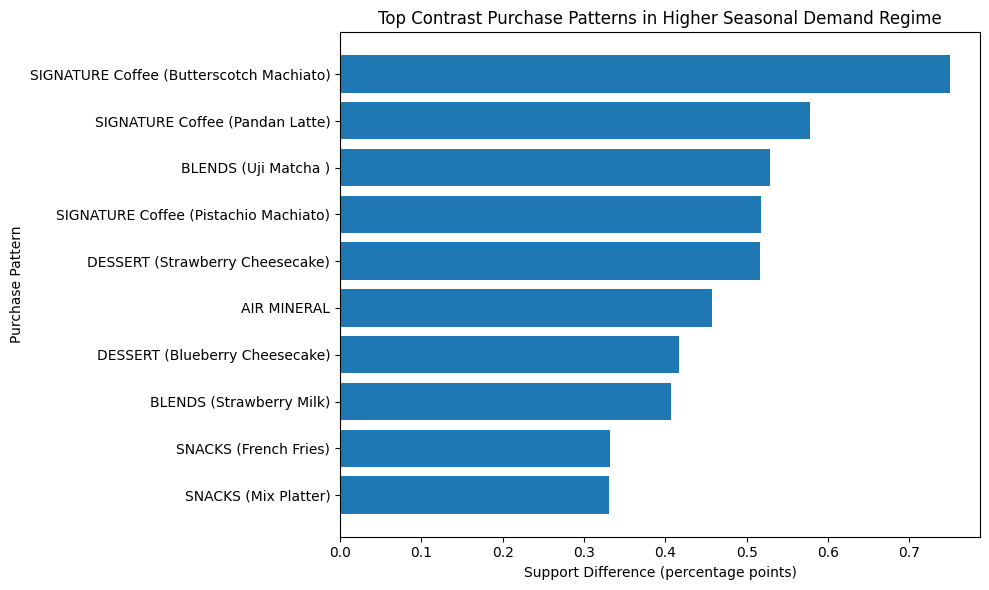

In [86]:
top_higher = (
    higher_emerging
    .head(10)
    .sort_values(
        "support_difference_higher"
    )
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_higher["pattern"],
    top_higher["support_difference_higher"] * 100
)

plt.title(
    "Top Contrast Purchase Patterns in "
    "Higher Seasonal Demand Regime"
)

plt.xlabel(
    "Support Difference (percentage points)"
)

plt.ylabel(
    "Purchase Pattern"
)

plt.tight_layout()
plt.show()

### Visualize Lower Emerging Patterns

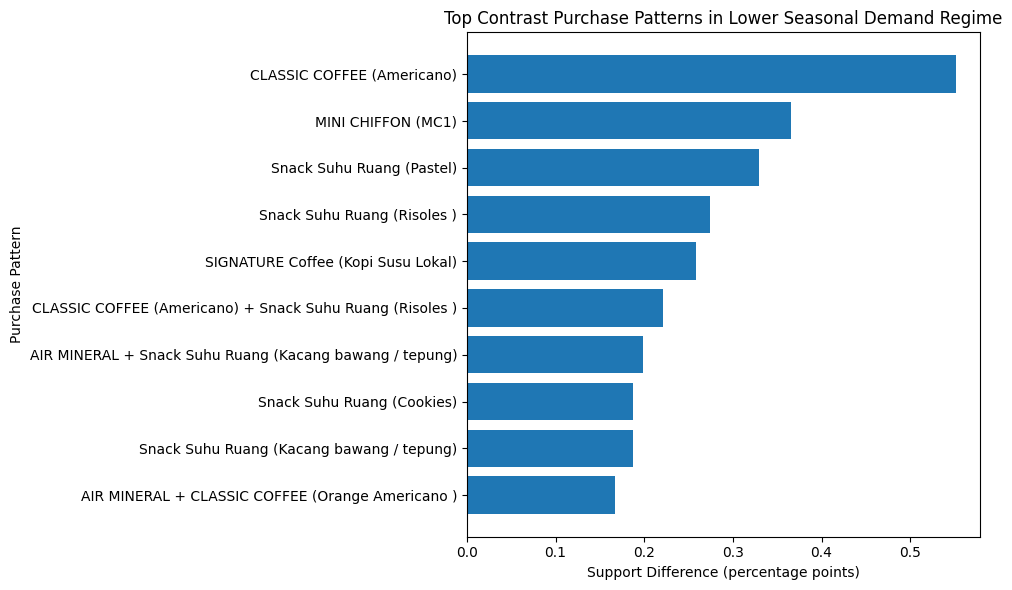

In [88]:
top_lower = (
    lower_emerging
    .head(10)
    .sort_values(
        "support_difference_lower"
    )
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_lower["pattern"],
    top_lower["support_difference_lower"] * 100
)

plt.title(
    "Top Contrast Purchase Patterns in "
    "Lower Seasonal Demand Regime"
)

plt.xlabel(
    "Support Difference (percentage points)"
)

plt.ylabel(
    "Purchase Pattern"
)

plt.tight_layout()
plt.show()

### Analyze Patterns by Size

For Higher:

In [90]:
higher_pattern_summary = (
    higher_significant
    .groupby("pattern_size")
    .size()
    .reset_index(name="number_of_patterns")
)

higher_pattern_summary

,pattern_size,number_of_patterns
0,1,213
1,2,8354
2,3,78243


For Lower:

In [92]:
lower_pattern_summary = (
    lower_significant
    .groupby("pattern_size")
    .size()
    .reset_index(name="number_of_patterns")
)

lower_pattern_summary

,pattern_size,number_of_patterns
0,1,168
1,2,6285
2,3,64892


### Comparison

In [93]:
pattern_size_comparison = pd.DataFrame({

    "Higher Seasonal Demand":
        higher_significant["pattern_size"]
        .value_counts()
        .sort_index(),

    "Lower Seasonal Demand":
        lower_significant["pattern_size"]
        .value_counts()
        .sort_index()

}).fillna(0)

pattern_size_comparison

,Higher Seasonal Demand,Lower Seasonal Demand
pattern_size,,
1,213,168
2,8354,6285
3,78243,64892


## Pattern Size Visualization

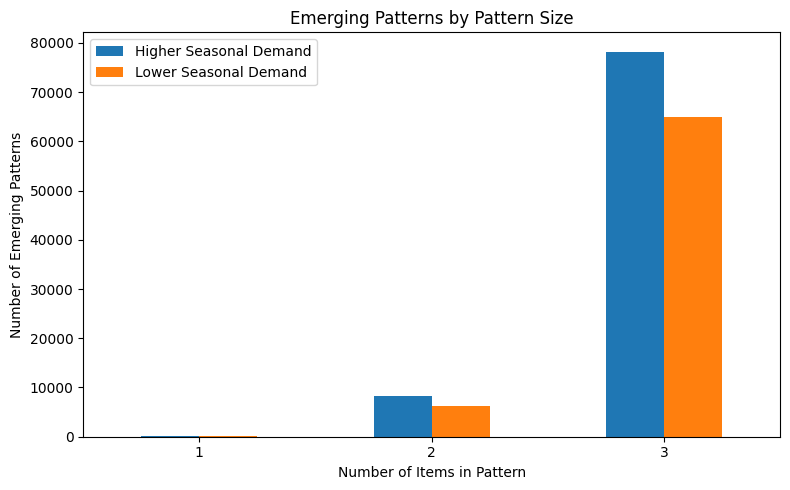

In [94]:
pattern_size_comparison.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title(
    "Emerging Patterns by Pattern Size"
)

plt.xlabel("Number of Items in Pattern")

plt.ylabel("Number of Emerging Patterns")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

# Final Result Table

## Higher Seasonal Demand

In [95]:
final_higher_results = (
    display_higher[
        [
            "pattern",
            "support_higher (%)",
            "support_lower (%)",
            "difference (%)",
            "growth_rate",
            "pattern_size"
        ]
    ]
    .rename(
        columns={
            "support_higher (%)":
                "Higher Support (%)",

            "support_lower (%)":
                "Lower Support (%)",

            "difference (%)":
                "Support Difference (%)",

            "growth_rate":
                "Growth Rate",

            "pattern_size":
                "Pattern Size"
        }
    )
)

final_higher_results

,pattern,Higher Support (%),Lower Support (%),Support Difference (%),Growth Rate,Pattern Size
144437,SIGNATURE Coffee (Butterscotch Machiato),10.99,10.24,0.75,1.07,1
48572,SIGNATURE Coffee (Pandan Latte),3.06,2.48,0.58,1.23,1
101798,BLENDS (Uji Matcha ),5.93,5.40,0.53,1.10,1
86535,SIGNATURE Coffee (Pistachio Machiato),6.09,5.58,0.52,1.09,1
69314,DESSERT (Strawberry Cheesecake),2.51,1.99,0.52,1.26,1
25076,AIR MINERAL,17.05,16.60,0.46,1.03,1
50913,DESSERT (Blueberry Cheesecake),3.18,2.76,0.42,1.15,1
12625,BLENDS (Strawberry Milk),4.87,4.47,0.41,1.09,1
87825,SNACKS (French Fries),2.71,2.38,0.33,1.14,1
84153,SNACKS (Mix Platter),5.57,5.24,0.33,1.06,1


## Lower Seasonal Demand

In [96]:
final_lower_results = (
    display_lower[
        [
            "pattern",
            "support_lower (%)",
            "support_higher (%)",
            "difference (%)",
            "growth_rate",
            "pattern_size"
        ]
    ]
    .rename(
        columns={
            "support_lower (%)":
                "Lower Support (%)",

            "support_higher (%)":
                "Higher Support (%)",

            "difference (%)":
                "Support Difference (%)",

            "growth_rate":
                "Growth Rate",

            "pattern_size":
                "Pattern Size"
        }
    )
)

final_lower_results

,pattern,Lower Support (%),Higher Support (%),Support Difference (%),Growth Rate,Pattern Size
54750,CLASSIC COFFEE (Americano),12.16,11.61,0.55,1.05,1
92648,MINI CHIFFON (MC1),4.14,3.77,0.37,1.10,1
136893,Snack Suhu Ruang (Pastel),3.69,3.36,0.33,1.10,1
148735,Snack Suhu Ruang (Risoles ),5.56,5.28,0.27,1.05,1
82004,SIGNATURE Coffee (Kopi Susu Lokal),8.69,8.43,0.26,1.03,1
118907,CLASSIC COFFEE (Americano) + Snack Suhu Ruang ...,0.88,0.66,0.22,1.33,2
148693,AIR MINERAL + Snack Suhu Ruang (Kacang bawang ...,0.96,0.77,0.20,1.26,2
151204,Snack Suhu Ruang (Cookies),1.97,1.79,0.19,1.10,1
104646,Snack Suhu Ruang (Kacang bawang / tepung),3.19,3.01,0.19,1.06,1
128104,AIR MINERAL + CLASSIC COFFEE (Orange Americano ),0.56,0.40,0.17,1.42,2
